# Image Processing

In [37]:
from PIL import Image
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pycocotools.coco import COCO
import matplotlib.patches as patches

In [17]:
DATA_DIR = Path('/Users/minkhant/Downloads/Grad-CAM_CarDD/data')
SPLIT_FOLDERS = {
    "train" : "train2017",
    "val" : "val2017",
    "test" : "test2017",
}

In [18]:
annotations = {}
image_records = []

for split, folder in SPLIT_FOLDERS.items():
    # Load the COCO annotations for this split.
    annotation_file = DATA_DIR / f"annotations/instances_{folder}.json"
    with open(annotation_file, "r") as f:
        annotations[split] = json.load(f)
    
    for image in annotations[split]["images"]:
        image_record = {
            "split" : split,
            "image_id" : image["id"],
            "file_name" : image["file_name"],
            "width" : image["width"],
            "height" : image["height"],
            }
        image_records.append(image_record)

image_df = pd.DataFrame(image_records)
    
print(image_df.head())
print(image_df.groupby("split").size())

   split  image_id   file_name  width  height
0  train         1  000001.jpg   1000     750
1  train         2  000002.jpg   1000     667
2  train         3  000003.jpg   1000     667
3  train         4  000004.jpg   1000     667
4  train         5  000005.jpg   1000     667
split
test      374
train    2816
val       810
dtype: int64


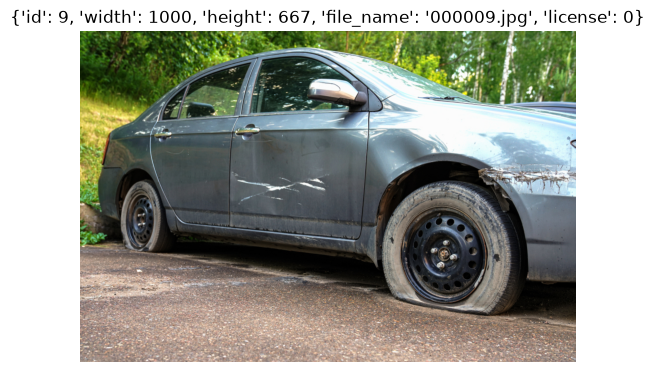

In [66]:
train_data = annotations["train"]
ann = train_data["annotations"][16]
images_by_id = {
    image["id"] : image
    for image in train_data["images"]
}
category_names = {
    category["id"] :category["name"]
    for category in train_data["categories"]
}

image_info = images_by_id[ann["image_id"]]
label = category_names[ann["category_id"]]

image_path = (
    DATA_DIR / SPLIT_FOLDERS["train"] / image_info["file_name"]
)

with Image.open(image_path) as img:
    original = img.convert("RGB")
    
plt.imshow(original)
plt.title(f"{image_info}")
plt.axis("off")
plt.show()

No adjustment: image=2, annotation=3, crop_box=(456, 195, 894, 633), external_padding=(0, 0, 0, 0)
Origin adjustment: image=1, annotation=1, crop_box=(156, 0, 380, 224), external_padding=(0, 0, 0, 0)
External padding: image=1, annotation=2, crop_box=(125, 0, 879, 754), external_padding=(0, 0, 0, 4)


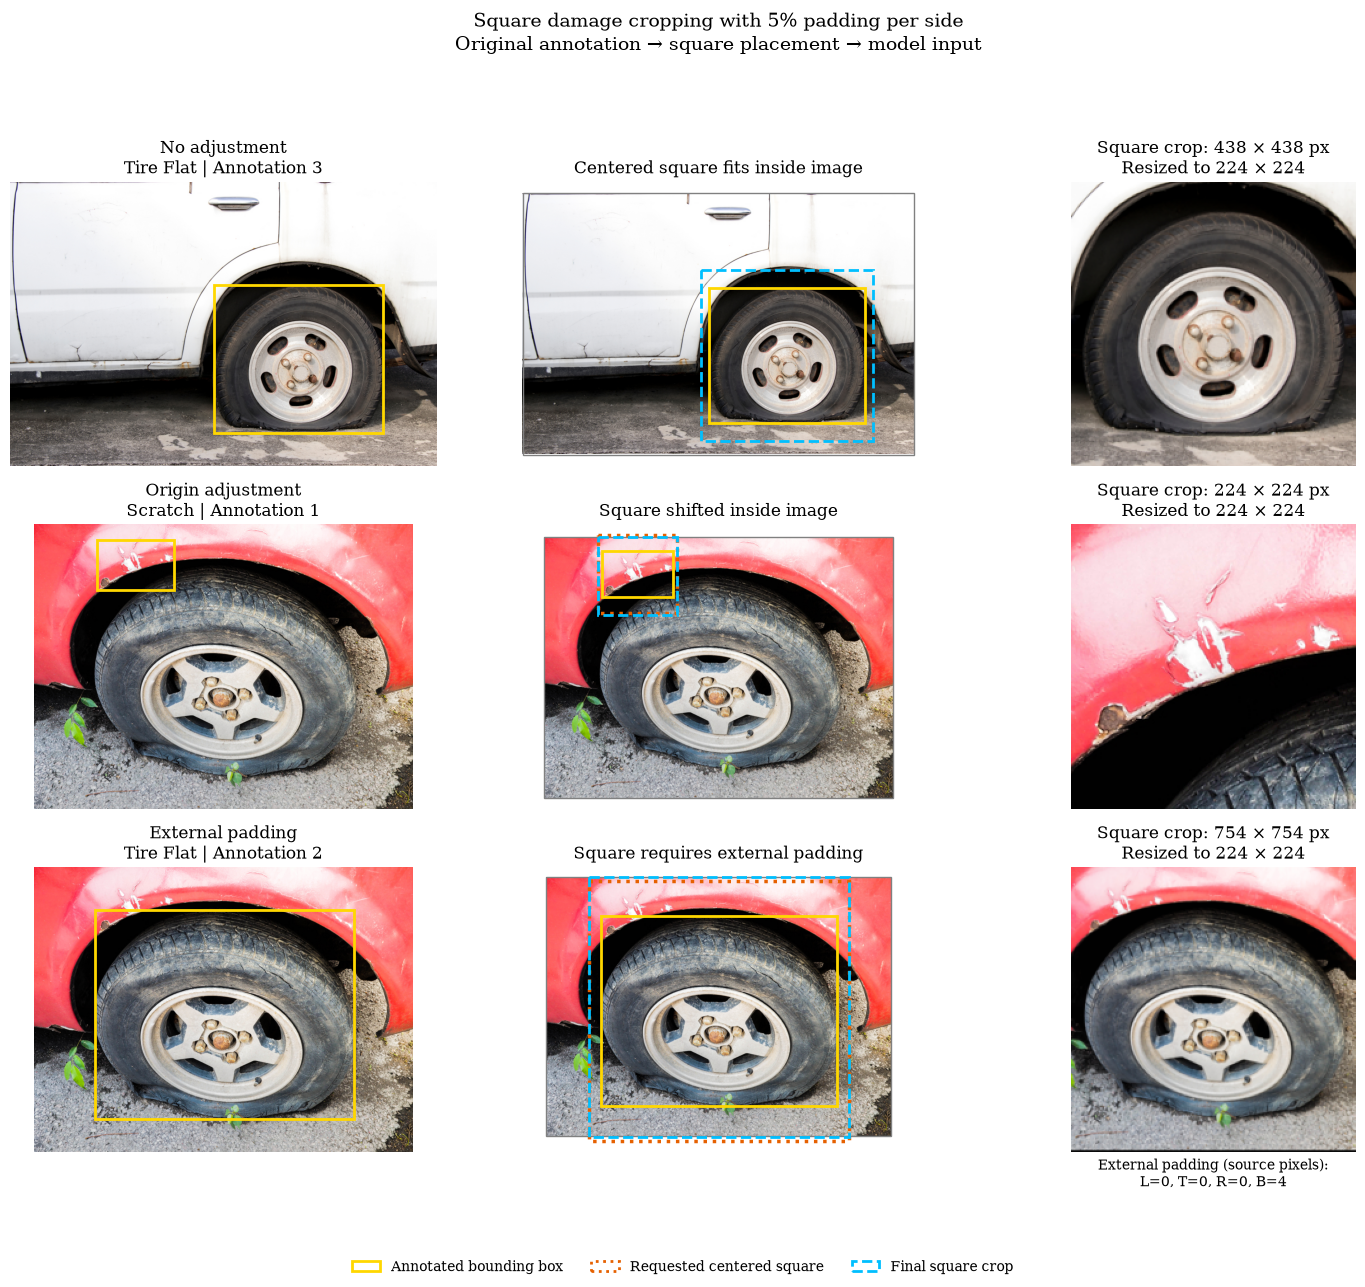

In [115]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from PIL import Image

DATA_DIR = Path("/Users/minkhant/Downloads/Grad-CAM_CarDD/data")
SPLIT = "train2017"
PADDING = 0.05

SAVE_FIGURE = True
OUTPUT_DIR = DATA_DIR.parent / "diagram"

# Optional: specify annotation IDs instead of selecting automatically.
EXAMPLE_IDS = {
    "no_adjustment": None,
    "origin_adjustment": None,
    "external_padding": None,
}

COLORS = {
    "bbox": "#FFD700",
    "requested": "#E66101",
    "final": "#00BFFF",
}

with (DATA_DIR / "annotations" / f"instances_{SPLIT}.json").open() as f:
    dataset = json.load(f)

images = {image["id"]: image for image in dataset["images"]}
categories = {
    category["id"]: category["name"]
    for category in dataset["categories"]
}


def square_crop_geometry(bbox, image_width, image_height, padding):
    """Construct a square, shift it where possible, and record padding."""
    x, y, width, height = map(float, bbox)

    if not all(math.isfinite(v) for v in (x, y, width, height, padding)):
        raise ValueError("Coordinates and padding must be finite.")

    if width <= 0 or height <= 0 or padding < 0:
        raise ValueError("Invalid bounding box or padding.")

    if (
        x < 0 or y < 0
        or x + width > image_width
        or y + height > image_height
    ):
        raise ValueError("The bounding box extends outside the image.")

    # Round the annotation outward to preserve its complete extent.
    x0, y0 = math.floor(x), math.floor(y)
    x1, y1 = math.ceil(x + width), math.ceil(y + height)

    longer_side = max(x1 - x0, y1 - y0)
    side = math.ceil((1 + 2 * padding) * longer_side)

    center_x = (x0 + x1) / 2
    center_y = (y0 + y1) / 2

    requested_left = math.floor(center_x - side / 2)
    requested_top = math.floor(center_y - side / 2)

    requested_box = (
        requested_left,
        requested_top,
        requested_left + side,
        requested_top + side,
    )

    def adjust_origin(origin, image_length):
        if side <= image_length:
            # The square fits: move it inside the image.
            return max(0, min(origin, image_length - side))

        # The square cannot fit: cover the image along this axis,
        # leaving the remaining region for external padding.
        return max(image_length - side, min(origin, 0))

    left = adjust_origin(requested_left, image_width)
    top = adjust_origin(requested_top, image_height)

    final_box = (left, top, left + side, top + side)
    right, bottom = final_box[2:]

    external_padding = (
        max(0, -left),
        max(0, -top),
        max(0, right - image_width),
        max(0, bottom - image_height),
    )

    if any(external_padding):
        case = "external_padding"
    elif requested_box != final_box:
        case = "origin_adjustment"
    else:
        case = "no_adjustment"

    return {
        "requested_box": requested_box,
        "final_box": final_box,
        "side": side,
        "external_padding": external_padding,
        "case": case,
    }


# Find examples of the three boundary-handling cases.
examples = {}

for annotation in dataset["annotations"]:
    if annotation.get("iscrowd", 0):
        continue

    info = images[annotation["image_id"]]

    try:
        geometry = square_crop_geometry(
            annotation["bbox"],
            info["width"],
            info["height"],
            PADDING,
        )
    except ValueError:
        continue

    case = geometry["case"]
    requested_id = EXAMPLE_IDS[case]

    if requested_id is not None:
        if annotation["id"] == requested_id:
            examples[case] = (annotation, geometry)
    elif case not in examples:
        examples[case] = (annotation, geometry)


def draw_bbox(ax, bbox):
    x, y, width, height = bbox
    ax.add_patch(Rectangle(
        (x, y), width, height,
        fill=False,
        edgecolor=COLORS["bbox"],
        linewidth=2,
    ))


def draw_square(ax, box, color, linestyle="-", linewidth=2):
    left, top, right, bottom = box
    ax.add_patch(Rectangle(
        (left, top),
        right - left,
        bottom - top,
        fill=False,
        edgecolor=color,
        linestyle=linestyle,
        linewidth=linewidth,
    ))


case_labels = {
    "no_adjustment": "No adjustment",
    "origin_adjustment": "Origin adjustment",
    "external_padding": "External padding",
}

case_order = list(case_labels)

with plt.rc_context({"font.family": "serif", "font.size": 10}):
    fig, axes = plt.subplots(3, 3, figsize=(15, 13))

    for row, case in enumerate(case_order):
        if case not in examples:
            for ax in axes[row]:
                ax.axis("off")

            axes[row, 1].text(
                0.5, 0.5,
                f"No matching example found:\n{case_labels[case]}",
                ha="center",
                va="center",
                transform=axes[row, 1].transAxes,
            )
            continue

        annotation, geometry = examples[case]
        info = images[annotation["image_id"]]

        with Image.open(DATA_DIR / SPLIT / info["file_name"]) as image:
            original = image.convert("RGB")

        # Verify geometry against the actual image dimensions.
        geometry = square_crop_geometry(
            annotation["bbox"],
            original.width,
            original.height,
            PADDING,
        )

        requested_box = geometry["requested_box"]
        final_box = geometry["final_box"]

        # Out-of-image areas are automatically filled with black by Pillow.
        crop = original.crop(final_box)
        assert crop.width == crop.height

        model_input = crop.resize(
            (224, 224),
            Image.Resampling.BILINEAR,
        )

        category = categories[annotation["category_id"]]

        # Column 1: original image and selected annotation.
        ax = axes[row, 0]
        ax.imshow(original)
        draw_bbox(ax, annotation["bbox"])
        ax.set_title(
            f"{case_labels[case]}\n"
            f"{category.title()} | Annotation {annotation['id']}"
        )

        # Column 2: requested and final square placement.
        ax = axes[row, 1]
        ax.imshow(original)

        # Mark the source-image boundary.
        ax.add_patch(Rectangle(
            (0, 0),
            original.width,
            original.height,
            fill=False,
            edgecolor="gray",
            linewidth=1,
        ))

        draw_bbox(ax, annotation["bbox"])

        # Show the requested square only when its position changed.
        if requested_box != final_box:
            draw_square(
                ax,
                requested_box,
                COLORS["requested"],
                linestyle=":",
                linewidth=2.5,
            )

        draw_square(
            ax,
            final_box,
            COLORS["final"],
            linestyle="--",
        )

        # Expand the view to reveal any square area outside the image.
        margin = 0.03 * max(original.size)
        ax.set_xlim(
            min(0, requested_box[0], final_box[0]) - margin,
            max(original.width, requested_box[2], final_box[2]) + margin,
        )
        ax.set_ylim(
            max(original.height, requested_box[3], final_box[3]) + margin,
            min(0, requested_box[1], final_box[1]) - margin,
        )

        if case == "no_adjustment":
            placement_title = "Centered square fits inside image"
        elif case == "origin_adjustment":
            placement_title = "Square shifted inside image"
        else:
            placement_title = "Square requires external padding"

        ax.set_title(placement_title)

        # Column 3: actual model input.
        ax = axes[row, 2]
        ax.imshow(model_input)
        ax.set_title(
            f"Square crop: {crop.width} × {crop.height} px\n"
            "Resized to 224 × 224"
        )

        if case == "external_padding":
            pad_left, pad_top, pad_right, pad_bottom = (
                geometry["external_padding"]
            )
            ax.set_xlabel(
                "External padding (source pixels):\n"
                f"L={pad_left}, T={pad_top}, "
                f"R={pad_right}, B={pad_bottom}"
            )

        for ax in axes[row]:
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)

        print(
            f"{case_labels[case]}: "
            f"image={info['id']}, "
            f"annotation={annotation['id']}, "
            f"crop_box={final_box}, "
            f"external_padding={geometry['external_padding']}"
        )

    legend_handles = [
        Patch(
            facecolor="none",
            edgecolor=COLORS["bbox"],
            linewidth=2,
            label="Annotated bounding box",
        ),
        Patch(
            facecolor="none",
            edgecolor=COLORS["requested"],
            linestyle=":",
            linewidth=2,
            label="Requested centered square",
        ),
        Patch(
            facecolor="none",
            edgecolor=COLORS["final"],
            linestyle="--",
            linewidth=2,
            label="Final square crop",
        ),
    ]

    fig.legend(
        handles=legend_handles,
        loc="lower center",
        ncol=3,
        frameon=False,
    )

    fig.suptitle(
        "Square damage cropping with 5% padding per side\n"
        "Original annotation → square placement → model input",
        fontsize=14,
    )

    fig.tight_layout(rect=(0, 0.06, 1, 0.94))

    if SAVE_FIGURE:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

        for extension in ("png", "pdf"):
            fig.savefig(
                OUTPUT_DIR / f"square_cropping_cases_p005.{extension}",
                dpi=300,
                bbox_inches="tight",
                facecolor="white",
            )

    plt.show()
    plt.close(fig)